# Lab C - Maximum Likelihood (ML) vs. Maximum A Posteriori (MAP) hypotheses
- **h_ML = argmax_h P(D | h)**: best explains the data.
- **h_MAP = argmax_h P(D | h) P(h)**: also uses a prior. Equal when the prior is uniform.

In [1]:
import sys; sys.path.insert(0, '../../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True); pd.set_option('display.width', 160)
from scipy.stats import beta

## 1. Classic example: a lab test
P(disease)=0.008. Test: P(+|disease)=0.98, P(+|no disease)=0.03. A patient tests positive.

In [2]:
prior = {'disease': 0.008, 'no disease': 0.992}; lik = {'disease': 0.98, 'no disease': 0.03}
post_unnorm = {h: lik[h]*prior[h] for h in prior}; Z = sum(post_unnorm.values())
print(pd.DataFrame({'prior P(h)': prior, 'likelihood P(+|h)': lik, 'P(+|h)P(h)': post_unnorm, 'posterior P(h|+)': {h: v/Z for h, v in post_unnorm.items()}}).round(4))
print('h_ML =', max(lik, key=lik.get), '| h_MAP =', max(post_unnorm, key=post_unnorm.get))

            prior P(h)  likelihood P(+|h)  P(+|h)P(h)  posterior P(h|+)
disease          0.008               0.98      0.0078            0.2085
no disease       0.992               0.03      0.0298            0.7915
h_ML = disease | h_MAP = no disease


The likelihood alone says *disease*, but the prior is so small that the most probable hypothesis is still *no disease* (posterior of disease ~ 0.21).

## 2. Coin toss: MLE vs. MAP with a Beta prior
Data: k heads in n tosses. MLE = k/n. With a Beta(a,b) prior the MAP estimate is (k+a-1)/(n+a+b-2).

In [3]:
def mle(k, n): return k / n
def map_est(k, n, a, b): return (k + a - 1) / (n + a + b - 2)
rows = []
for k, n in [(3, 3), (7, 10), (70, 100), (700, 1000)]:
    rows.append(dict(data=f'{k}/{n}', MLE=mle(k, n), **{f'MAP Beta({a},{b})': map_est(k, n, a, b) for a, b in [(1, 1), (5, 5), (20, 20)]}))
pd.DataFrame(rows).set_index('data').round(3)

,MLE,"MAP Beta(1,1)","MAP Beta(5,5)","MAP Beta(20,20)"
data,,,,
3/3,1.0,1.0,0.636,0.537
7/10,0.7,0.7,0.611,0.542
70/100,0.7,0.7,0.685,0.645
700/1000,0.7,0.7,0.698,0.693


Beta(1,1) is uniform, so MAP = MLE. A strong 'fair coin' prior Beta(20,20) pulls 3/3 heads far from 1.0, but with 1000 tosses the data dominates and all estimates agree.

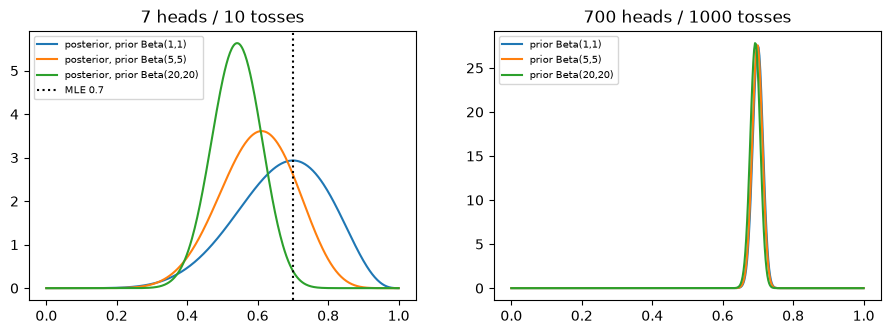

In [4]:
p = np.linspace(0, 1, 400); fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a_, b_ in [(1, 1), (5, 5), (20, 20)]: ax[0].plot(p, beta.pdf(p, a_ + 7, b_ + 3), label=f'posterior, prior Beta({a_},{b_})')
ax[0].axvline(0.7, color='k', ls=':', label='MLE 0.7'); ax[0].set_title('7 heads / 10 tosses'); ax[0].legend(fontsize=7)
for a_, b_ in [(1, 1), (5, 5), (20, 20)]: ax[1].plot(p, beta.pdf(p, a_ + 700, b_ + 300), label=f'prior Beta({a_},{b_})')
ax[1].set_title('700 heads / 1000 tosses'); ax[1].legend(fontsize=7); plt.show()

## 3. Discrete hypothesis space: which coin bias? (h in {0.3, 0.5, 0.8}); data: 7 heads, 3 tails

In [5]:
from scipy.stats import binom
H = np.array([0.3, 0.5, 0.8]); L = binom.pmf(7, 10, H)
for name, pr in [('uniform prior', np.array([1/3, 1/3, 1/3])), ('prior favouring fair coin', np.array([0.1, 0.8, 0.1]))]:
    post = L * pr / (L * pr).sum()
    print(f'{name:28s} likelihood {L.round(3)} posterior {post.round(3)} -> h_ML={H[L.argmax()]}  h_MAP={H[post.argmax()]}')

uniform prior                likelihood [0.009 0.117 0.201] posterior [0.027 0.358 0.615] -> h_ML=0.8  h_MAP=0.8
prior favouring fair coin    likelihood [0.009 0.117 0.201] posterior [0.008 0.817 0.175] -> h_ML=0.8  h_MAP=0.5


## 4. Link to regression: Ridge regression is MAP with a Gaussian prior on the weights
Minimizing `||y - Xw||^2 + alpha ||w||^2` equals MAP when w ~ N(0, sigma^2/alpha). Few data points -> prior matters, coefficients shrink toward 0.

In [6]:
from sklearn.linear_model import LinearRegression, Ridge
rng = np.random.default_rng(0); X = rng.normal(size=(8, 5)); w_true = np.array([2., -1., 0., 0., 1.]); y = X @ w_true + rng.normal(0, 1, 8)
print(pd.DataFrame({'true': w_true, 'OLS (=ML)': LinearRegression(fit_intercept=False).fit(X, y).coef_, 'Ridge alpha=5 (=MAP)': Ridge(5, fit_intercept=False).fit(X, y).coef_}).round(3))

   true  OLS (=ML)  Ridge alpha=5 (=MAP)
0   2.0      1.667                 0.327
1  -1.0     -0.589                -0.359
2   0.0     -0.326                -0.006
3   0.0      0.838                 0.226
4   1.0      0.940                 0.724
